# CNN Transfer Learning — ResNet18, ResNet50, VGG16

Ce notebook implémente des classifieurs **Transfer Learning** pour la détection
de sons cardiaques anormaux (PCG) à partir de spectrogrammes Mel.

- **Backbones** : ResNet18 (implémentation légère), ResNet50 et VGG16 (pré-entraînés ImageNet).
- **Adaptation** : entrée Mel 1 canal → 3 canaux, redimensionnement, tête de classification binaire.
- **Entraînement** : phase de transfert (backbone gelé) puis **fine-tuning** (dégel partiel, LR réduit).
  Chaque backbone possède **sa propre cellule d'entraînement** (§7.1, §7.2, §7.3) : on peut
  n'en exécuter qu'une seule, ou toutes à la suite.
- **Vitesse** : cache Mel chargé une fois dans un tenseur TensorFlow, pipeline `tf.data`
  vectorisé (gather → augmentation → resize → RGB → `preprocess_input`), AUC calculée
  pendant la validation (aucun `predict` supplémentaire par epoch), *mixed precision*
  `float16` sur GPU, `steps_per_execution=4`, allocateur CUDA asynchrone et **XLA
  désactivé** (`jit_compile=False`) car ses compilations étaient très lentes sur ce GPU.
- **Validation** : exactement la même **Stratified 3-Fold Cross-Validation** au niveau enregistrement que les notebooks précédents (`KFold(3, shuffle=True, random_state=10)` par classe via `fold_utils.build_3fold_recording_splits`).
- **Suivi MLflow** : paramètres, métriques par pli, moyennes ± écart-type, artefacts et modèles dans l'expérience `tp3_audio_engine`.
- **Métriques** : Accuracy, Precision, Recall, F1-score, AUC, balanced accuracy, matrices de confusion.
- **Courbes** : Loss et Accuracy par pli.

## 1. Imports et configuration

In [1]:
import gc
import json
import os
import random
import sys
import time
from datetime import datetime
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
# --- Réglages d'environnement AVANT l'import de TensorFlow -------------------
# XLA (jit_compile) : compilations de plusieurs minutes et pas à 3-6 s sur ce GPU -> OFF.
os.environ.setdefault("TF_XLA_FLAGS", "--tf_xla_auto_jit=0")
# Allocateur CUDA asynchrone : limite la fragmentation mémoire (GPU 4 Go / WDDM).
os.environ.setdefault("TF_GPU_ALLOCATOR", "cuda_malloc_async")

# --- localisation du dépôt AVANT les imports locaux
DATA_ROOT = next((p / "ourdataset" / "train" for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "ourdataset" / "train").is_dir()), None)
assert DATA_ROOT is not None, f"ourdataset/train introuvable depuis {Path.cwd()}"
AUDIO_ENGINE_DIR = DATA_ROOT.parent.parent / "audio_engine"
sys.path.insert(0, str(AUDIO_ENGINE_DIR))
assert (AUDIO_ENGINE_DIR / "preprocess.py").exists(), f"preprocess.py introuvable dans {AUDIO_ENGINE_DIR}"

import librosa
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score, roc_curve)

from preprocess import AudioError, Preprocessor
from fold_utils import (build_3fold_recording_splits, plot_all_folds_training,
                        plot_training_history, save_history_csv)

MODEL_DIR = AUDIO_ENGINE_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)
PLOT_DIR = MODEL_DIR / "plots"
PLOT_DIR.mkdir(exist_ok=True)

# --- mêmes paramètres Mel que CNN.ipynb / registry.py
SR, N_MELS, N_FFT, HOP, T = 2000, 128, 512, 128, 256
DOWN = 2   # 128×256 -> 64×128 (cache réutilisé)
INPUT_H, INPUT_W = N_MELS // DOWN, T // DOWN  # 64x128
IMG_SIZE = 128  # taille d'entrée des backbones transfer learning
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE
USE_MIXED_PRECISION = True   # float16 sur GPU (ignoré sur CPU) -> epochs plus rapides
USE_XLA = False              # XLA désactivé : voir §7 (compilations très lentes, pas de gain)
STEPS_PER_EXECUTION = 4      # pas de gradient groupés dans un seul appel tf.function

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.backend.set_floatx("float32")


def configure_tensorflow_gpu():
    '''Active le GPU TensorFlow (croissance mémoire + mixed precision) et affiche le diagnostic.'''
    gpus = tf.config.list_physical_devices("GPU")
    if gpus:
        for gpu in gpus:
            try:
                tf.config.experimental.set_memory_growth(gpu, True)
            except Exception as exc:
                print(f"  mémoire dynamique indisponible pour {gpu}: {exc}")
        try:
            tf.config.set_visible_devices(gpus, "GPU")
        except Exception:
            pass
    build = {}
    try:
        build = tf.sysconfig.get_build_info()
    except Exception:
        pass
    cuda_build = build.get("is_cuda_build", build.get("cuda_version") is not None)
    print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
    print("Build CUDA :", cuda_build, "| CUDA", build.get("cuda_version"), "| cuDNN", build.get("cudnn_version"))
    print("Allocateur GPU :", os.environ.get("TF_GPU_ALLOCATOR", "défaut"))
    if gpus:
        if USE_MIXED_PRECISION:
            try:
                keras.mixed_precision.set_global_policy("mixed_float16")
                print("Mixed precision : mixed_float16 (activée)")
            except Exception as exc:
                print("Mixed precision non activée :", exc)
        logical = []
        try:
            logical = tf.config.list_logical_devices("GPU")
        except Exception:
            logical = gpus
        print("GPU détecté(s) :", [d.name for d in logical], "-> entraînement sur GPU")
    else:
        print("GPU : aucun détecté -> entraînement sur CPU")
        if sys.platform.startswith("win"):
            print("  Note: sur Windows natif, TensorFlow >= 2.11 ne supporte pas le GPU NVIDIA.")
            print("  -> Utiliser WSL2 avec tensorflow[and-cuda] (voir requirements-train.txt).")
    # Keras 3 utilise jit_compile="auto" (= XLA sur GPU) : on le coupe explicitement.
    tf.config.optimizer.set_jit(USE_XLA)
    print("XLA (jit_compile) :", "activé" if USE_XLA else "désactivé")


configure_tensorflow_gpu()

MEL_CACHE = MODEL_DIR / "tp3_cnn_mels_64x128.npy"
INDEX_CACHE = MODEL_DIR / "tp3_cnn_mels_index.npz"
pre = Preprocessor({"max_segments": 10})


def mel(seg):
    '''Mel 128×256 dB normalisé, puis réduit à 64×128 (identique à CNN.ipynb).'''
    m = librosa.feature.melspectrogram(y=seg, sr=SR, n_fft=N_FFT, hop_length=HOP,
                                       n_mels=N_MELS, fmin=20, fmax=SR // 2)
    m = librosa.power_to_db(m, ref=np.max)
    m = np.pad(m, ((0, 0), (0, max(0, T - m.shape[1]))))[:, :T].astype(np.float32)
    m = (m - m.mean()) / (m.std() + 1e-6)
    return m[::DOWN, ::DOWN]


TensorFlow 2.20.0 | Keras 3.12.4
Build CUDA : True | CUDA 12.5.1 | cuDNN 9
Allocateur GPU : cuda_malloc_async
Mixed precision : mixed_float16 (activée)
GPU détecté(s) : ['/device:GPU:0'] -> entraînement sur GPU
XLA (jit_compile) : désactivé


I0000 00:00:1795459281.665419    1132 gpu_process_state.cc:208] Using CUDA malloc Async allocator for GPU: 0
I0000 00:00:1795459281.666419    1132 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


## 2. Cache des spectrogrammes Mel (réutilisé)

In [2]:
files = [(p, label) for label, name in enumerate(["normal", "abnormal"])
         for p in sorted((DATA_ROOT / name).glob("*.wav"))]
print(len(files), "fichiers WAV")


def build_mel_cache(force=False):
    if MEL_CACHE.exists() and INDEX_CACHE.exists() and not force:
        index = np.load(INDEX_CACHE, allow_pickle=True)
        X = np.load(MEL_CACHE, mmap_mode="r")
        print(f"Cache réutilisé : {MEL_CACHE.name} {X.shape} ({X.nbytes / 1e9:.2f} Go, mmap)")
        return X, index["keys"], index["y"].astype(np.int64)

    t0, keys, labels, blocks = time.time(), [], [], []
    for n, (path, label) in enumerate(files, start=1):
        try:
            segments = pre.segment(pre.load_clean(path.read_bytes()))
        except AudioError as error:
            print(f"  ignoré {path.name}: {error}")
            continue
        blocks.append(np.stack([mel(s) for s in segments]).astype(np.float16))
        keys += [f"{label}/{path.name}"] * len(segments)
        labels += [label] * len(segments)
        if n % 500 == 0:
            print(f"  {n}/{len(files)} fichiers, {sum(len(b) for b in blocks)} segments ({time.time() - t0:.0f} s)")

    X_all = np.concatenate(blocks).astype(np.float16)
    X_all = X_all[:, None, :, :]                      # (N, 1, 64, 128)
    keys_all = np.array(keys, dtype=object)
    y_all = np.array(labels, dtype=np.int64)
    np.save(MEL_CACHE, X_all)
    np.savez(INDEX_CACHE, keys=keys_all, y=y_all)
    print(f"Cache écrit : {MEL_CACHE.name} {X_all.shape} ({X_all.nbytes / 1e9:.2f} Go) en {(time.time() - t0) / 60:.1f} min")
    return X_all, keys_all, y_all


X_mel, keys_all, y_all = build_mel_cache()
print(f"{len(y_all)} segments pour {len(np.unique(keys_all))} enregistrements | abnormal = {y_all.mean():.1%} des segments")


3784 fichiers WAV
  ignoré 296_1311682952647_A1.wav: Enregistrement trop court (< 1.0 s)
  500/3784 fichiers, 1818 segments (33 s)
  1000/3784 fichiers, 3461 segments (47 s)
  1500/3784 fichiers, 6912 segments (70 s)
  2000/3784 fichiers, 10392 segments (95 s)
  2500/3784 fichiers, 13824 segments (134 s)
  ignoré 171_1307971016233_E.wav: Enregistrement trop court (< 1.0 s)
  3000/3784 fichiers, 17126 segments (155 s)
  ignoré 201104021355.wav: Enregistrement trop court (< 1.0 s)
  3500/3784 fichiers, 20269 segments (169 s)
Cache écrit : tp3_cnn_mels_64x128.npy (22126, 1, 64, 128) (0.36 Go) en 3.1 min
22126 segments pour 3781 enregistrements | abnormal = 23.3% des segments


## 3. Découpage Stratified 3-Fold (au niveau enregistrement)

Même protocole que les notebooks précédents : `build_3fold_recording_splits(keys_all, n_splits=3, seed=10)`. Les segments d'un même WAV restent dans le même pli (pas de fuite de données).

In [3]:
folds, recording_keys = build_3fold_recording_splits(keys_all, n_splits=3, seed=10)

for fold in folds:
    pos_tr, pos_va = fold["train_pos"], fold["test_pos"]
    print(f"pli {fold['fold']} : {len(fold['train_keys']):>4} WAV / {len(pos_tr):>5} segments en train | "
          f"{len(fold['test_keys']):>3} WAV / {len(pos_va):>4} segments en validation "
          f"(abnormal train={y_all[pos_tr].mean():.1%}, val={y_all[pos_va].mean():.1%})")


pli 1 : 2520 WAV / 14740 segments en train | 1261 WAV / 7386 segments en validation (abnormal train=23.4%, val=23.1%)
pli 2 : 2521 WAV / 14962 segments en train | 1260 WAV / 7164 segments en validation (abnormal train=23.2%, val=23.4%)
pli 3 : 2521 WAV / 14550 segments en train | 1260 WAV / 7576 segments en validation (abnormal train=23.3%, val=23.4%)


## 4. Adaptation des données aux backbones pré-entraînés

Les backbones ImageNet attendent des images RGB. On adapte les Mel 64×128×1 :
- redimensionnement à `IMG_SIZE×IMG_SIZE` ;
- conversion 1 canal → 3 canaux ;
- prétraitement spécifique au backbone (`preprocess_input`).

**Optimisation vitesse** : le cache Mel est converti une seule fois en tenseur TensorFlow
(`X_TF`), puis chaque lot est construit dans le graphe `tf.data`
(`gather` → augmentation → resize → RGB → `preprocess_input`) avec
`num_parallel_calls=AUTOTUNE` et `prefetch`. Les deux étapes `load` et `prepare` sont
fusionnées en **un seul `map`** (moins de dispatch Python par lot) et `random_erase`
construit son rectangle de façon **séparable lignes × colonnes** : 2 comparaisons sur
`(B, H)` et `(B, W)` au lieu de 4 sur `(B, H, W)`, pour un masque identique. Plus de
générateur Python échantillon par échantillon : les epochs sont nettement plus rapides.

In [4]:
# --- Cache TensorFlow en mémoire (construit une seule fois) -----------------
def build_tf_cache(mels, labels):
    '''Convertit le cache Mel (N, 1, 64, 128) en tenseurs (N, 64, 128) + labels.'''
    t0 = time.time()
    arr = np.ascontiguousarray(np.asarray(mels)[:, 0])      # (N, 64, 128), float16
    x = tf.constant(arr, dtype=tf.float16)
    y = tf.constant(np.asarray(labels, dtype=np.int64))
    print(f"Cache TF prêt : X={tuple(x.shape)} {x.dtype} | {time.time() - t0:.1f} s "
          f"({arr.nbytes / 1e9:.2f} Go)")
    return x, y


X_TF, Y_TF = build_tf_cache(X_mel, y_all)


def random_erase(x, prob=0.5, max_frac=0.10):
    '''SpecAugment vectorisé : masque un rectangle aléatoire par échantillon du lot.

    Rectangle construit de façon séparable (masque lignes × masque colonnes) :
    résultat identique au masque 2D complet, mais 2 comparaisons sur (B, H) et (B, W)
    au lieu de 4 comparaisons sur (B, H, W).
    '''
    shape = tf.shape(x)
    b, h, w = shape[0], shape[1], shape[2]
    eh = tf.maximum(tf.cast(tf.cast(h, tf.float32) * max_frac, tf.int32), 1)
    ew = tf.maximum(tf.cast(tf.cast(w, tf.float32) * max_frac, tf.int32), 1)
    top = tf.random.uniform([b], 0, tf.maximum(h - eh, 1), dtype=tf.int32)
    left = tf.random.uniform([b], 0, tf.maximum(w - ew, 1), dtype=tf.int32)
    rows = tf.range(h)[None, :]
    cols = tf.range(w)[None, :]
    in_rows = tf.cast(tf.logical_and(rows >= top[:, None], rows < (top + eh)[:, None]), x.dtype)
    in_cols = tf.cast(tf.logical_and(cols >= left[:, None], cols < (left + ew)[:, None]), x.dtype)
    mask = in_rows[:, :, None] * in_cols[:, None, :]            # (B, H, W) : 1 dans le rectangle
    mask = mask * tf.cast(tf.random.uniform([b, 1, 1]) < prob, x.dtype)
    return x * (1.0 - mask[..., None])


def make_transfer_dataset(indices, batch_size=32, shuffle=False, augment=False,
                          seed=42, img_size=IMG_SIZE, preprocess_fn=None):
    '''Dataset tf.data rapide et vectorisé pour le transfer learning.'''
    idx = tf.constant(np.asarray(indices, dtype=np.int64))
    ds = tf.data.Dataset.from_tensor_slices(idx)
    if shuffle:
        ds = ds.shuffle(int(idx.shape[0]), seed=seed, reshuffle_each_iteration=True)
    ds = ds.batch(batch_size)

    @tf.autograph.experimental.do_not_convert
    def load_and_prepare(i):
        '''gather -> augmentation -> resize -> RGB -> preprocess_input, en un seul map.'''
        x = tf.gather(X_TF, i)                     # (B, 64, 128) float16
        y = tf.gather(Y_TF, i)
        x = tf.cast(x, tf.float32)[..., None]      # (B, 64, 128, 1)
        if augment:
            x = random_erase(x)
        x = tf.image.resize(x, (img_size, img_size))
        x = tf.image.grayscale_to_rgb(x)           # (B, H, W, 1) -> (B, H, W, 3)
        if preprocess_fn is not None:
            x = preprocess_fn(x * 255.0)
        return x, y

    ds = ds.map(load_and_prepare, num_parallel_calls=AUTOTUNE, deterministic=False)
    return ds.prefetch(AUTOTUNE)


Cache TF prêt : X=(22126, 64, 128) <dtype: 'float16'> | 4.1 s (0.36 Go)


2026-11-23 19:45:16.851203: E tensorflow/core/util/util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


## 5. Modèles Transfer Learning

Chaque modèle : entrée Mel adaptée → backbone ImageNet (gelé en phase 1) → GAP → Dropout → Dense softmax. Phase 2 : fine-tuning avec dégel partiel et LR réduit.

In [5]:
# --- ResNet18 léger (non présent dans keras.applications) ---
def _resnet_basic_block(x, filters, stride=1, name="block"):
    shortcut = x
    x = layers.Conv2D(filters, 3, strides=stride, padding="same", use_bias=False, name=f"{name}_conv1")(x)
    x = layers.BatchNormalization(name=f"{name}_bn1")(x)
    x = layers.ReLU(name=f"{name}_relu1")(x)
    x = layers.Conv2D(filters, 3, strides=1, padding="same", use_bias=False, name=f"{name}_conv2")(x)
    x = layers.BatchNormalization(name=f"{name}_bn2")(x)
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, 1, strides=stride, padding="same", use_bias=False, name=f"{name}_proj")(shortcut)
        shortcut = layers.BatchNormalization(name=f"{name}_proj_bn")(shortcut)
    x = layers.Add(name=f"{name}_add")([x, shortcut])
    x = layers.ReLU(name=f"{name}_relu2")(x)
    return x


def build_resnet18_backbone(input_tensor):
    x = layers.Conv2D(64, 7, strides=2, padding="same", use_bias=False, name="stem_conv")(input_tensor)
    x = layers.BatchNormalization(name="stem_bn")(x)
    x = layers.ReLU(name="stem_relu")(x)
    x = layers.MaxPooling2D(3, strides=2, padding="same", name="stem_pool")(x)
    for i, stride in enumerate([1, 1]): x = _resnet_basic_block(x, 64, stride=stride, name=f"layer1_{i}")
    for i, stride in enumerate([2, 1]): x = _resnet_basic_block(x, 128, stride=stride, name=f"layer2_{i}")
    for i, stride in enumerate([2, 1]): x = _resnet_basic_block(x, 256, stride=stride, name=f"layer3_{i}")
    for i, stride in enumerate([2, 1]): x = _resnet_basic_block(x, 512, stride=stride, name=f"layer4_{i}")
    return keras.Model(input_tensor, x, name="resnet18_backbone")


BACKBONE_SPECS = {
    "ResNet18": {
        "builder": "custom_resnet18",
        "preprocess": keras.applications.resnet.preprocess_input,
        "unfreeze_from": "layer4_0_conv1",
    },
    "ResNet50": {
        "builder": keras.applications.ResNet50,
        "preprocess": keras.applications.resnet.preprocess_input,
        "unfreeze_from": "conv5_block1_1_conv",
    },
    "VGG16": {
        "builder": keras.applications.VGG16,
        "preprocess": keras.applications.vgg16.preprocess_input,
        "unfreeze_from": "block5_conv1",
    },
}


def build_transfer_model(backbone_name, n_classes=2, dropout=0.4, img_size=IMG_SIZE):
    spec = BACKBONE_SPECS[backbone_name]
    inputs = keras.Input(shape=(img_size, img_size, 3), name="mel_rgb")
    if spec["builder"] == "custom_resnet18":
        base = build_resnet18_backbone(inputs)
        x = base.output
        base.trainable = True  # pas de poids ImageNet; entraîné from scratch avec 2 phases LR
    else:
        base = spec["builder"](include_top=False, weights="imagenet", input_tensor=inputs)
        x = base.output
        base.trainable = False
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(dropout, name="head_dropout")(x)
    outputs = layers.Dense(n_classes, activation="softmax", dtype="float32", name="classifier")(x)
    model = keras.Model(inputs, outputs, name=f"tl_{backbone_name.lower()}")
    return model, base


def unfreeze_for_finetuning(model, base, backbone_name):
    spec = BACKBONE_SPECS[backbone_name]
    if spec["builder"] == "custom_resnet18":
        for layer in model.layers:
            layer.trainable = True
        return
    base.trainable = True
    unfreeze = False
    for layer in base.layers:
        if layer.name == spec["unfreeze_from"]:
            unfreeze = True
        layer.trainable = unfreeze
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

## 6. Helpers (métriques, seuil, AUC)

L'AUC est calculée comme **métrique Keras** (`BinaryAUC` sur P(abnormal)) pendant la
validation : plus besoin d'un `predict()` complet à chaque epoch, ce qui raccourcit
sensiblement l'entraînement. Le reste est identique à `CNN.ipynb` pour garantir une
évaluation cohérente.

In [6]:
@keras.utils.register_keras_serializable()
class BinaryAUC(keras.metrics.AUC):
    '''AUC sur P(abnormal) calculée pendant la validation : aucun predict() en plus.

    Le `sample_weight` (class_weight) est ignoré pour garder une AUC non pondérée.
    '''
    def update_state(self, y_true, y_pred, sample_weight=None):
        proba = y_pred[:, 1] if len(y_pred.shape) > 1 else y_pred
        super().update_state(tf.reshape(tf.cast(y_true, tf.float32), [-1]),
                             tf.reshape(tf.cast(proba, tf.float32), [-1]))


def select_threshold(y_true, proba, min_spec=0.80):
    fpr, tpr, thr = roc_curve(y_true, proba, drop_intermediate=False)
    ok = np.isfinite(thr) & (thr <= 1) & ((1 - fpr) >= min_spec)
    if ok.any():
        indices = np.where(ok)[0]
        return float(thr[indices[np.argmax(tpr[indices])]])
    return 0.5


def classification_metrics(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "accuracy": float(accuracy_score(y_true, pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, pred)),
        "macro_precision": float(precision_score(y_true, pred, average="macro", zero_division=0)),
        "macro_recall": float(recall_score(y_true, pred, average="macro", zero_division=0)),
        "macro_f1": float(f1_score(y_true, pred, average="macro", zero_division=0)),
        "precision": float(precision_score(y_true, pred, zero_division=0)),
        "recall": float(recall_score(y_true, pred, zero_division=0)),
        "specificity": float(tn / (tn + fp)) if (tn + fp) else float("nan"),
        "f1": float(f1_score(y_true, pred, zero_division=0)),
        "auc": float(roc_auc_score(y_true, proba)),
        "threshold": float(threshold),
        "confusion": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    }


def merge_histories(h1, h2):
    out = {}
    for k in set(h1) | set(h2):
        out[k] = [float(v) for v in h1.get(k, [])] + [float(v) for v in h2.get(k, [])]
    return out

## 7. Entraînement 3 folds + fine-tuning (une cellule par backbone)

La fonction `run_backbone` ci-dessous contient la boucle commune ; les cellules
**§7.1**, **§7.2** et **§7.3** lancent chacune l'entraînement d'un seul backbone.
On peut donc exécuter uniquement le modèle voulu, ou les trois à la suite
(les résultats s'accumulent dans `all_results`).

Pour chaque backbone et chaque pli :
1. **Phase transfert** : backbone gelé (ou LR normal pour ResNet18 custom), entraînement de la tête.
2. **Fine-tuning** : dégel partiel + LR réduit.
3. Évaluation sur le pli de validation (hors entraînement).

Optimisations de temps appliquées :
- **XLA désactivé** (`jit_compile=False`, `TF_XLA_FLAGS=--tf_xla_auto_jit=0`) : le
  `jit_compile="auto"` de Keras 3 déclenchait des compilations de plusieurs minutes et
  des pas à 3-6 s au lieu de ~0,1 s sur ce GPU ;
- **allocateur CUDA asynchrone** (`TF_GPU_ALLOCATOR=cuda_malloc_async`) : évite la
  fragmentation mémoire qui dégradait les epochs au fil des plis (GPU 4 Go) ;
- `steps_per_execution=4` : plusieurs pas de gradient par appel `tf.function`, donc moins
  de surcoût CPU/pilote entre les pas ;
- pipeline `tf.data` vectorisé : un seul `map` fusionné (`gather` → augmentation → resize
  → RGB → `preprocess_input`), `AUTOTUNE` et `prefetch` ;
- taille de lot adaptée au backbone (64 pour ResNet18, 32 pour ResNet50/VGG16) pour mieux
  remplir le GPU sans dépasser sa mémoire ;
- AUC de validation calculée comme **métrique Keras** (plus de `predict()` par epoch) ;
- *mixed precision* `float16` sur GPU, sortie softmax en `float32` ;
- early stopping `patience=2` sur `val_auc` ;
- seul le **meilleur pli** est conservé en mémoire/sur disque (`SAVE_FOLD_MODELS=False`).

Les prédictions out-of-fold servent au choix du seuil, comme dans `CNN.ipynb`.

In [7]:
EPOCHS_HEAD = 5        # phase 1 : tête de classification (backbone gelé)
EPOCHS_FINETUNE = 5    # phase 2 : fine-tuning partiel
BS = 32                # taille de lot par défaut
# Lot plus grand quand la mémoire GPU le permet (ResNet18 est bien plus léger).
BATCH_SIZE_BY_BACKBONE = {"ResNet18": 64, "ResNet50": 32, "VGG16": 32}
PATIENCE = 2           # early stopping sur val_auc
LR_HEAD = 1e-3
LR_FINETUNE = 1e-5
SAVE_FOLD_MODELS = False   # True = archiver chaque pli (écriture disque lourde)

all_results = {}   # backbone -> {fold_rows, fold_outputs, histories, fold_models, train_seconds}


def _early_stop():
    return keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=PATIENCE,
                                         restore_best_weights=True, verbose=1)


def _metrics():
    '''Métriques neuves pour chaque phase : AUC calculée pendant la validation.'''
    return [keras.metrics.SparseCategoricalAccuracy(name="accuracy"), BinaryAUC(name="auc")]


def run_backbone(backbone_name):
    '''Entraîne UN backbone sur les 3 plis (appelée par les cellules §7.1, §7.2, §7.3).'''
    spec = BACKBONE_SPECS[backbone_name]
    preprocess_fn = spec["preprocess"]
    tag = backbone_name.lower()
    batch_size = BATCH_SIZE_BY_BACKBONE.get(backbone_name, BS)
    fold_rows, fold_outputs, histories = [], [], []
    best = {"fold": None, "auc": -1.0, "model": None}
    t_start = time.time()
    print(f"\n{'#' * 80}\n# Backbone: {backbone_name} | batch={batch_size} | "
          f"steps_per_execution={STEPS_PER_EXECUTION} | XLA={'on' if USE_XLA else 'off'}"
          f"\n{'#' * 80}")

    for fold in folds:
        k = fold["fold"]
        pos_tr, pos_va = fold["train_pos"], fold["test_pos"]
        y_tr, y_va = y_all[pos_tr], y_all[pos_va]
        print("=" * 78)
        print(f"[{backbone_name}] PLI {k}/3 | train={len(pos_tr)} segments | validation={len(pos_va)} segments")

        counts = np.bincount(y_tr, minlength=2)
        class_weight = {i: float(len(y_tr) / (2 * counts[i])) for i in range(2) if counts[i] > 0}

        # Libère graphes/allocations du pli précédent AVANT de reconstruire le modèle.
        keras.backend.clear_session()
        gc.collect()
        tf.random.set_seed(SEED + k)
        model, base = build_transfer_model(backbone_name, n_classes=2, dropout=0.4, img_size=IMG_SIZE)

        # Datasets construits une seule fois par pli (après clear_session) et réutilisés
        # par les deux phases : aucun rebuild entre les deux model.fit().
        train_ds = make_transfer_dataset(pos_tr, batch_size=batch_size, shuffle=True, augment=True,
                                         seed=SEED + k, preprocess_fn=preprocess_fn)
        val_ds = make_transfer_dataset(pos_va, batch_size=batch_size, shuffle=False, augment=False,
                                       seed=SEED + k, preprocess_fn=preprocess_fn)

        # Phase 1 : tête de classification (backbone gelé)
        # jit_compile=False -> pas de XLA ; steps_per_execution -> moins d'appels tf.function
        model.compile(optimizer=keras.optimizers.Adam(LR_HEAD),
                      loss=keras.losses.SparseCategoricalCrossentropy(),
                      metrics=_metrics(),
                      jit_compile=USE_XLA, steps_per_execution=STEPS_PER_EXECUTION)
        h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD,
                       class_weight=class_weight, callbacks=[_early_stop()], verbose=2)

        # Phase 2 : fine-tuning (dégel partiel, LR réduit)
        unfreeze_for_finetuning(model, base, backbone_name)
        model.compile(optimizer=keras.optimizers.Adam(LR_FINETUNE),
                      loss=keras.losses.SparseCategoricalCrossentropy(),
                      metrics=_metrics(),
                      jit_compile=USE_XLA, steps_per_execution=STEPS_PER_EXECUTION)
        h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINETUNE,
                       class_weight=class_weight, callbacks=[_early_stop()], verbose=2)

        hist = merge_histories(h1.history, h2.history)
        best_epoch = int(np.argmax(hist.get("val_auc", hist["val_loss"]))) + 1

        proba = model.predict(val_ds, verbose=0)[:, 1]
        m = classification_metrics(y_va, proba, threshold=0.5)

        plot_training_history(hist, k, PLOT_DIR, f"tl_{tag}")
        save_history_csv(hist, MODEL_DIR / f"tl_{tag}_fold{k}_history.csv")
        if SAVE_FOLD_MODELS:
            model.save(MODEL_DIR / f"tl_{tag}_fold{k}.keras")

        row = {
            "fold": k, "backbone": backbone_name,
            "epochs_run": len(hist["loss"]), "best_epoch": best_epoch,
            "accuracy": m["accuracy"],
            "balanced_accuracy": m["balanced_accuracy"],
            "precision": m["precision"],
            "recall": m["recall"],
            "f1": m["f1"],
            "macro_precision": m["macro_precision"],
            "macro_recall": m["macro_recall"],
            "macro_f1": m["macro_f1"],
            "roc_auc": m["auc"],
            "specificity": m["specificity"],
            "confusion": m["confusion"],
        }
        fold_rows.append(row)
        fold_outputs.append({"fold": k, "y_true": y_va, "proba": proba,
                             "y_pred": (proba >= 0.5).astype(int)})
        histories.append({"fold": k, "steps": list(range(1, len(hist["loss"]) + 1)), "metrics": hist})

        # On ne garde en mémoire/que le meilleur pli (limite la RAM et l'I/O disque)
        auc_value = float(m["auc"]) if np.isfinite(m["auc"]) else -1.0
        if best["model"] is None or auc_value > best["auc"]:
            best.update(fold=k, auc=auc_value, model=model)
            model.save(MODEL_DIR / f"best_tl_{tag}.keras")
        else:
            del model
        del train_ds, val_ds
        gc.collect()
        keras.backend.clear_session()

        print(f"[{backbone_name}] pli {k} : Acc={m['accuracy']:.3f} P={m['precision']:.3f} "
              f"R={m['recall']:.3f} F1={m['f1']:.3f} AUC={m['auc']:.3f}")

    all_results[backbone_name] = {
        "fold_rows": fold_rows, "fold_outputs": fold_outputs, "histories": histories,
        "fold_models": {best["fold"]: (best["model"], best["auc"])},
        "train_seconds": time.time() - t_start,
    }
    print(f"[{backbone_name}] terminé en {all_results[backbone_name]['train_seconds'] / 60:.1f} min")
    return all_results[backbone_name]


### 7.1 Entraînement — ResNet18 (backbone léger, sans poids ImageNet)

In [8]:
run_backbone("ResNet18")


################################################################################
# Backbone: ResNet18 | batch=64 | steps_per_execution=4 | XLA=off
################################################################################
[ResNet18] PLI 1/3 | train=14740 segments | validation=7386 segments
Epoch 1/5
231/231 - 88s - 379ms/step - accuracy: 0.7509 - auc: 0.8383 - loss: 0.5211 - val_accuracy: 0.2411 - val_auc: 0.7091 - val_loss: 0.9290
Epoch 2/5
231/231 - 50s - 217ms/step - accuracy: 0.7914 - auc: 0.8980 - loss: 0.3695 - val_accuracy: 0.6082 - val_auc: 0.8509 - val_loss: 0.6295
Epoch 3/5
231/231 - 50s - 216ms/step - accuracy: 0.8117 - auc: 0.9190 - loss: 0.3311 - val_accuracy: 0.8503 - val_auc: 0.9077 - val_loss: 0.4126
Epoch 4/5
231/231 - 50s - 216ms/step - accuracy: 0.8247 - auc: 0.9307 - loss: 0.3033 - val_accuracy: 0.4651 - val_auc: 0.8396 - val_loss: 0.7485
Epoch 5/5
231/231 - 51s - 219ms/step - accuracy: 0.8301 - auc: 0.9352 - loss: 0.2927 - val_accuracy: 0.8551 - val_auc: 0.8

{'fold_rows': [{'fold': 1,
   'backbone': 'ResNet18',
   'epochs_run': 10,
   'best_epoch': 10,
   'accuracy': 0.8533712428919578,
   'balanced_accuracy': 0.8829296558955138,
   'precision': 0.6208769887466046,
   'recall': 0.9378663540445487,
   'f1': 0.747139855241653,
   'macro_precision': 0.7994174920859245,
   'macro_recall': 0.8829296558955138,
   'macro_f1': 0.821944415179221,
   'roc_auc': 0.9479411934679589,
   'specificity': 0.8279929577464789,
   'confusion': {'tn': 4703, 'fp': 977, 'fn': 106, 'tp': 1600}},
  {'fold': 2,
   'backbone': 'ResNet18',
   'epochs_run': 9,
   'best_epoch': 9,
   'accuracy': 0.8153266331658291,
   'balanced_accuracy': 0.8593544145248588,
   'precision': 0.5633903133903134,
   'recall': 0.9422275163787969,
   'f1': 0.7051482059282371,
   'macro_precision': 0.770561088742907,
   'macro_recall': 0.8593544145248588,
   'macro_f1': 0.7853553243847059,
   'roc_auc': 0.9226975621965368,
   'specificity': 0.7764813126709207,
   'confusion': {'tn': 4259, 'f

### 7.2 Entraînement — ResNet50 (poids ImageNet + fine-tuning)

In [9]:
run_backbone("ResNet50")


################################################################################
# Backbone: ResNet50 | batch=32 | steps_per_execution=4 | XLA=off
################################################################################
[ResNet50] PLI 1/3 | train=14740 segments | validation=7386 segments
Epoch 1/5
461/461 - 76s - 166ms/step - accuracy: 0.7042 - auc: 0.7676 - loss: 0.6287 - val_accuracy: 0.8293 - val_auc: 0.9023 - val_loss: 0.3795
Epoch 2/5
461/461 - 63s - 136ms/step - accuracy: 0.7720 - auc: 0.8511 - loss: 0.4853 - val_accuracy: 0.8374 - val_auc: 0.9056 - val_loss: 0.3515
Epoch 3/5
461/461 - 61s - 131ms/step - accuracy: 0.7832 - auc: 0.8606 - loss: 0.4719 - val_accuracy: 0.8184 - val_auc: 0.9062 - val_loss: 0.4000
Epoch 4/5
461/461 - 61s - 133ms/step - accuracy: 0.7840 - auc: 0.8616 - loss: 0.4704 - val_accuracy: 0.8393 - val_auc: 0.9101 - val_loss: 0.3440
Epoch 5/5
461/461 - 61s - 132ms/step - accuracy: 0.7848 - auc: 0.8614 - loss: 0.4746 - val_accuracy: 0.8155 - val_auc: 0.9

{'fold_rows': [{'fold': 1,
   'backbone': 'ResNet50',
   'epochs_run': 10,
   'best_epoch': 10,
   'accuracy': 0.8334687246141349,
   'balanced_accuracy': 0.8788068829153113,
   'precision': 0.5846975088967972,
   'recall': 0.963071512309496,
   'f1': 0.7276350752878654,
   'macro_precision': 0.7854650131896573,
   'macro_recall': 0.8788068829153113,
   'macro_f1': 0.8038526390479889,
   'roc_auc': 0.9438702260456053,
   'specificity': 0.7945422535211267,
   'confusion': {'tn': 4513, 'fp': 1167, 'fn': 63, 'tp': 1643}},
  {'fold': 2,
   'backbone': 'ResNet50',
   'epochs_run': 10,
   'best_epoch': 9,
   'accuracy': 0.8375209380234506,
   'balanced_accuracy': 0.8690958013706774,
   'precision': 0.5989243180945063,
   'recall': 0.9285288862418106,
   'f1': 0.7281644091546007,
   'macro_precision': 0.7863071491809958,
   'macro_recall': 0.8690958013706774,
   'macro_f1': 0.806148698704316,
   'roc_auc': 0.9333150185437245,
   'specificity': 0.8096627164995442,
   'confusion': {'tn': 4441, 

### 7.3 Entraînement — VGG16 (poids ImageNet + fine-tuning)

In [10]:
run_backbone("VGG16")


################################################################################
# Backbone: VGG16 | batch=32 | steps_per_execution=4 | XLA=off
################################################################################
[VGG16] PLI 1/3 | train=14740 segments | validation=7386 segments
Epoch 1/5
461/461 - 114s - 248ms/step - accuracy: 0.6639 - auc: 0.6928 - loss: 3.4898 - val_accuracy: 0.7823 - val_auc: 0.8900 - val_loss: 0.8462
Epoch 2/5
461/461 - 74s - 160ms/step - accuracy: 0.7469 - auc: 0.8171 - loss: 0.7586 - val_accuracy: 0.8314 - val_auc: 0.9000 - val_loss: 0.3689
Epoch 3/5
461/461 - 74s - 161ms/step - accuracy: 0.7476 - auc: 0.8226 - loss: 0.6432 - val_accuracy: 0.7910 - val_auc: 0.8912 - val_loss: 0.6074
Epoch 4/5
461/461 - 72s - 157ms/step - accuracy: 0.7493 - auc: 0.8181 - loss: 0.6518 - val_accuracy: 0.8283 - val_auc: 0.8885 - val_loss: 0.3634
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 2.
Epoch 1/5
461/461 - 141s - 306ms/step - accu

{'fold_rows': [{'fold': 1,
   'backbone': 'VGG16',
   'epochs_run': 9,
   'best_epoch': 9,
   'accuracy': 0.8570268074735987,
   'balanced_accuracy': 0.8906378481911399,
   'precision': 0.6249039200614912,
   'recall': 0.9531066822977726,
   'f1': 0.754874651810585,
   'macro_precision': 0.8040907560173677,
   'macro_recall': 0.8906378481911399,
   'macro_f1': 0.8269786103089622,
   'roc_auc': 0.9510796608490333,
   'specificity': 0.828169014084507,
   'confusion': {'tn': 4704, 'fp': 976, 'fn': 80, 'tp': 1626}},
  {'fold': 2,
   'backbone': 'VGG16',
   'epochs_run': 10,
   'best_epoch': 9,
   'accuracy': 0.8403126744835288,
   'balanced_accuracy': 0.88166416286119,
   'precision': 0.5995534052847041,
   'recall': 0.9594997022036926,
   'f1': 0.7379752633989922,
   'macro_precision': 0.7921823314116172,
   'macro_recall': 0.88166416286119,
   'macro_f1': 0.8115694425808453,
   'roc_auc': 0.9487604126908462,
   'specificity': 0.8038286235186873,
   'confusion': {'tn': 4409, 'fp': 1076, '

## 8. Évaluation OOF, Mean ± Std et matrices de confusion

Pour chaque backbone : seuil OOF (rappel max, spécificité ≥ 0.80), métriques par pli à ce seuil, agrégation par enregistrement, puis moyenne ± écart-type.


=== ResNet18 (seuil OOF=0.4860) ===
Segment OOF : Acc=0.835 P=0.591 R=0.951 F1=0.729 AUC=0.941
Recording   : Acc=0.743 P=0.466 R=0.943 F1=0.624 AUC=0.885
  accuracy_at_threshold: 0.835 ± 0.018
  precision_at_threshold: 0.592 ± 0.027
  recall_at_threshold: 0.951 ± 0.007
  f1_at_threshold: 0.729 ± 0.020
  auc_at_threshold: 0.940 ± 0.012


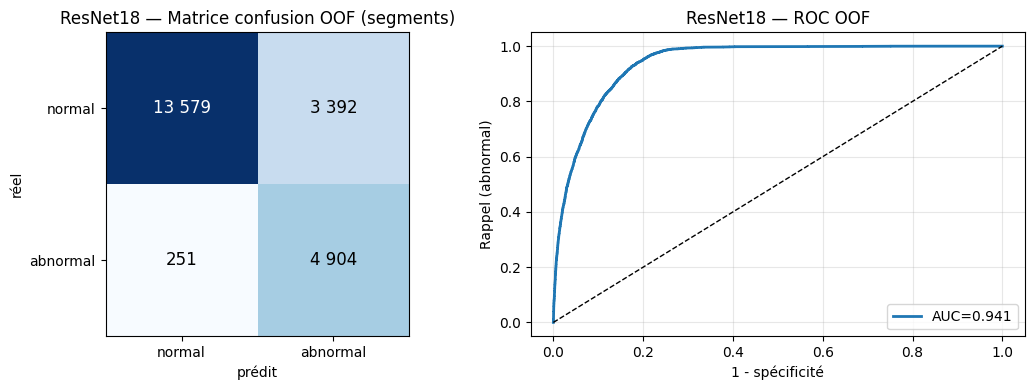


=== ResNet50 (seuil OOF=0.4856) ===
Segment OOF : Acc=0.836 P=0.592 R=0.953 F1=0.731 AUC=0.940
Recording   : Acc=0.741 P=0.465 R=0.942 F1=0.622 AUC=0.889
  accuracy_at_threshold: 0.836 ± 0.003
  precision_at_threshold: 0.592 ± 0.007
  recall_at_threshold: 0.953 ± 0.016
  f1_at_threshold: 0.730 ± 0.005
  auc_at_threshold: 0.940 ± 0.005


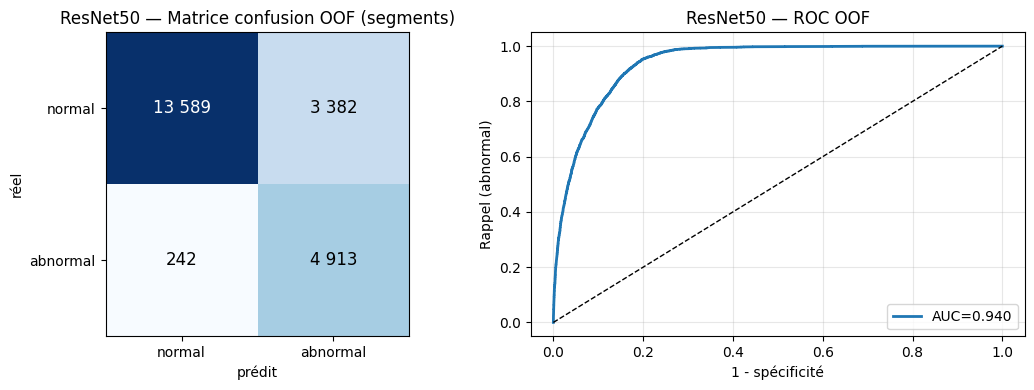


=== VGG16 (seuil OOF=0.4255) ===
Segment OOF : Acc=0.840 P=0.596 R=0.969 F1=0.738 AUC=0.952
Recording   : Acc=0.756 P=0.480 R=0.972 F1=0.643 AUC=0.924
  accuracy_at_threshold: 0.839 ± 0.009
  precision_at_threshold: 0.596 ± 0.013
  recall_at_threshold: 0.969 ± 0.002
  f1_at_threshold: 0.738 ± 0.010
  auc_at_threshold: 0.953 ± 0.004


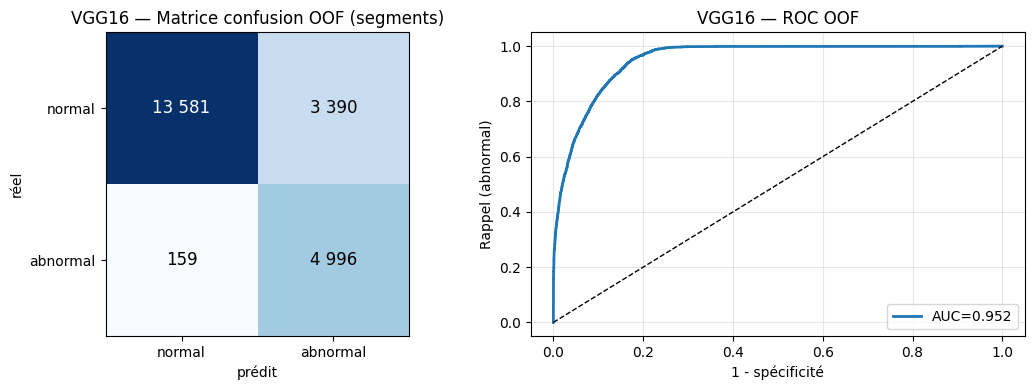


=== Résumé Mean ± Std (segment, seuil OOF) ===
backbone  threshold  accuracy_at_threshold_mean  precision_at_threshold_mean  recall_at_threshold_mean  f1_at_threshold_mean  auc_at_threshold_mean  accuracy_at_threshold_std  precision_at_threshold_std  recall_at_threshold_std  f1_at_threshold_std  auc_at_threshold_std
ResNet18   0.485999                    0.835032                     0.592094                  0.951245              0.729465               0.940134                   0.017930                    0.026624                 0.006712             0.019533              0.012352
ResNet50   0.485636                    0.836169                     0.592363                  0.952846              0.730450               0.939811                   0.003404                    0.007162                 0.015751             0.005236              0.004641
   VGG16   0.425466                    0.839412                     0.595825                  0.969206              0.737875               

In [11]:
summary_rows = []

for backbone_name, res in all_results.items():
    fold_rows = res["fold_rows"]
    fold_outputs = res["fold_outputs"]
    tag = backbone_name.lower()

    oof_true = np.concatenate([o["y_true"] for o in fold_outputs])
    oof_proba = np.concatenate([o["proba"] for o in fold_outputs])
    threshold = select_threshold(oof_true, oof_proba, min_spec=0.80)
    oof = classification_metrics(oof_true, oof_proba, threshold)
    res["threshold"] = threshold
    res["oof_metrics"] = oof

    # Metrics per fold at OOF threshold
    for row, out in zip(fold_rows, fold_outputs):
        m = classification_metrics(out["y_true"], out["proba"], threshold)
        row.update({
            "accuracy_at_threshold": m["accuracy"],
            "precision_at_threshold": m["precision"],
            "recall_at_threshold": m["recall"],
            "f1_at_threshold": m["f1"],
            "specificity_at_threshold": m["specificity"],
            "auc_at_threshold": m["auc"],
        })

    # Recording-level aggregation
    oof_pos = np.concatenate([f["test_pos"] for f in folds])
    per_key = {}
    for pos, proba in zip(oof_pos, oof_proba):
        per_key.setdefault(keys_all[pos], []).append(float(proba))
    rec_keys = sorted(per_key)
    rec_proba = np.array([np.mean(per_key[k]) for k in rec_keys])
    y_rec = np.array([int(k[0]) for k in rec_keys])
    rec_m = classification_metrics(y_rec, rec_proba, threshold)
    res["recording_metrics"] = rec_m

    # Mean ± Std (segment-level at OOF threshold)
    metric_names = ["accuracy_at_threshold", "precision_at_threshold", "recall_at_threshold", "f1_at_threshold", "auc_at_threshold"]
    means = {m: float(np.mean([r[m] for r in fold_rows])) for m in metric_names}
    stds = {m: float(np.std([r[m] for r in fold_rows])) for m in metric_names}
    res["mean_std"] = {"mean": means, "std": stds}

    summary_rows.append({"backbone": backbone_name, **{f"{m}_mean": means[m] for m in metric_names}, **{f"{m}_std": stds[m] for m in metric_names}, "threshold": threshold})

    print(f"\n=== {backbone_name} (seuil OOF={threshold:.4f}) ===")
    print(f"Segment OOF : Acc={oof['accuracy']:.3f} P={oof['precision']:.3f} R={oof['recall']:.3f} F1={oof['f1']:.3f} AUC={oof['auc']:.3f}")
    print(f"Recording   : Acc={rec_m['accuracy']:.3f} P={rec_m['precision']:.3f} R={rec_m['recall']:.3f} F1={rec_m['f1']:.3f} AUC={rec_m['auc']:.3f}")
    for m in metric_names:
        print(f"  {m}: {means[m]:.3f} ± {stds[m]:.3f}")

    # Confusion matrix plot (OOF, segment-level)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    cm = np.array([[oof["confusion"]["tn"], oof["confusion"]["fp"]],
                   [oof["confusion"]["fn"], oof["confusion"]["tp"]]])
    axes[0].imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            axes[0].text(j, i, f"{cm[i,j]:,}".replace(",", " "), ha="center", va="center",
                         color="white" if cm[i,j] > cm.max()/2 else "black", fontsize=12)
    axes[0].set_xticks([0,1], ["normal","abnormal"]); axes[0].set_yticks([0,1], ["normal","abnormal"])
    axes[0].set_xlabel("prédit"); axes[0].set_ylabel("réel")
    axes[0].set_title(f"{backbone_name} — Matrice confusion OOF (segments)")

    fpr, tpr, _ = roc_curve(oof_true, oof_proba)
    axes[1].plot(fpr, tpr, lw=2, label=f"AUC={oof['auc']:.3f}")
    axes[1].plot([0,1],[0,1],"k--", lw=1)
    axes[1].set_xlabel("1 - spécificité"); axes[1].set_ylabel("Rappel (abnormal)")
    axes[1].set_title(f"{backbone_name} — ROC OOF"); axes[1].legend(); axes[1].grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"tl_{tag}_oof_confusion_roc.png", dpi=150)
    plt.show()

# Summary table
import pandas as pd
summary_df = pd.DataFrame(summary_rows)
cols = ["backbone", "threshold"] + [c for c in summary_df.columns if c.endswith("_mean") or c.endswith("_std")]
print("\n=== Résumé Mean ± Std (segment, seuil OOF) ===")
print(summary_df[cols].to_string(index=False))


## 9. Courbes d'entraînement (Loss & Accuracy) par backbone

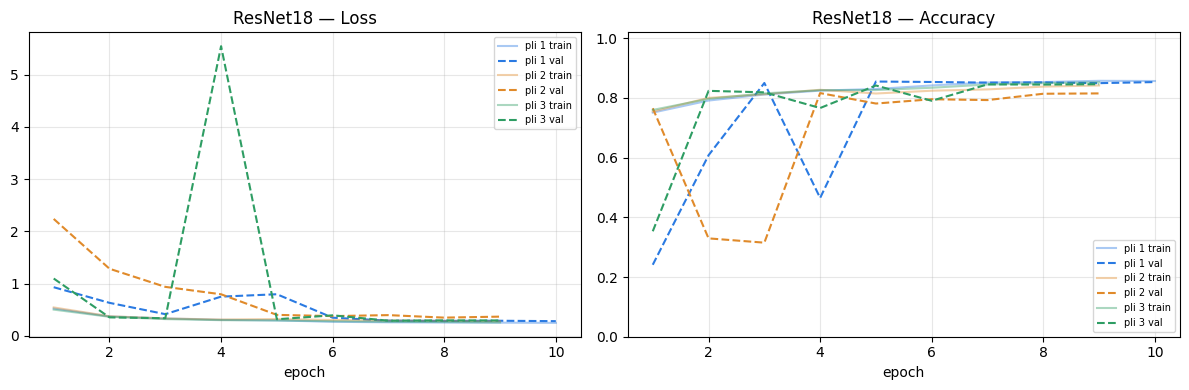

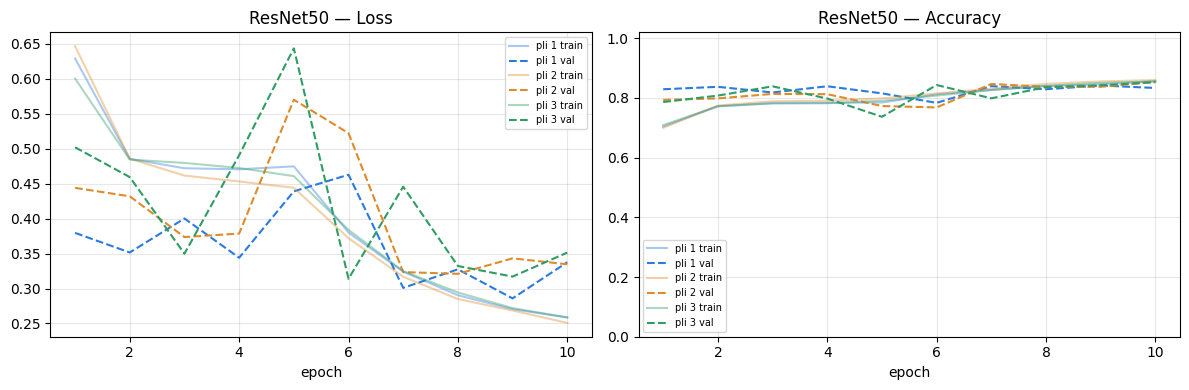

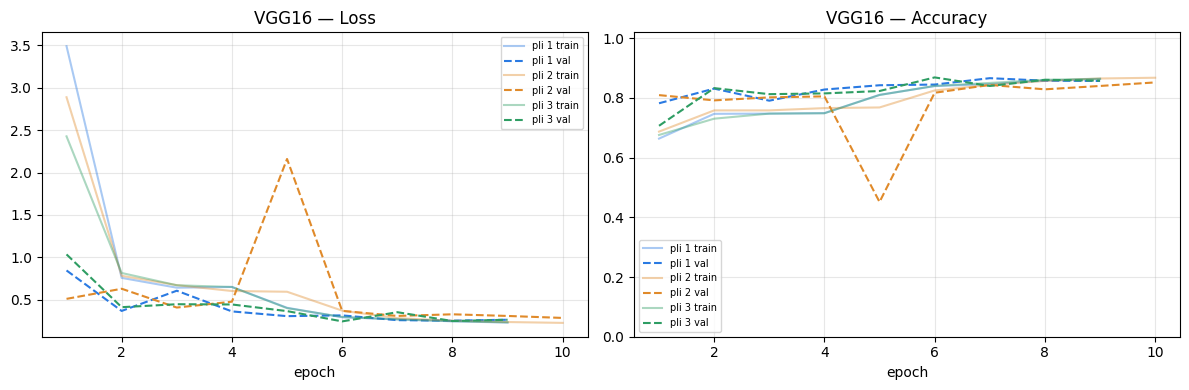

In [12]:
for backbone_name, res in all_results.items():
    tag = backbone_name.lower()
    histories = res["histories"]
    plot_all_folds_training(histories, PLOT_DIR, f"tl_{tag}")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    palette = ["#2a7ae2", "#e08a2a", "#2e9d63"]
    for i, entry in enumerate(histories):
        h = entry["metrics"]
        fold = entry["fold"]
        epochs = np.arange(1, len(h["loss"]) + 1)
        c = palette[i % len(palette)]
        axes[0].plot(epochs, h["loss"], color=c, alpha=0.4, label=f"pli {fold} train")
        axes[0].plot(epochs, h["val_loss"], color=c, linestyle="--", label=f"pli {fold} val")
        acc_key = "accuracy" if "accuracy" in h else "sparse_categorical_accuracy"
        val_acc_key = "val_accuracy" if "val_accuracy" in h else "val_sparse_categorical_accuracy"
        if acc_key in h:
            axes[1].plot(epochs, h[acc_key], color=c, alpha=0.4, label=f"pli {fold} train")
        if val_acc_key in h:
            axes[1].plot(epochs, h[val_acc_key], color=c, linestyle="--", label=f"pli {fold} val")
    axes[0].set_title(f"{backbone_name} — Loss"); axes[0].set_xlabel("epoch"); axes[0].grid(alpha=0.3); axes[0].legend(fontsize=7)
    axes[1].set_title(f"{backbone_name} — Accuracy"); axes[1].set_xlabel("epoch"); axes[1].set_ylim(0,1.02); axes[1].grid(alpha=0.3); axes[1].legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"tl_{tag}_loss_accuracy.png", dpi=150)
    plt.show()


## 10. Sauvegarde des meilleurs modèles et MLflow

Pour chaque backbone : sauvegarde du meilleur pli (AUC validation), méta JSON, et enregistrement MLflow dans `tp3_audio_engine`.

In [13]:
import mlflow
from mlflow_utils import log_tensorflow_run

for backbone_name, res in all_results.items():
    tag = backbone_name.lower()
    fold_rows = res["fold_rows"]
    fold_outputs = res["fold_outputs"]
    histories = res["histories"]
    fold_models = res["fold_models"]
    threshold = res["threshold"]
    oof = res["oof_metrics"]
    rec_m = res["recording_metrics"]

    best_fold = next(iter(fold_models))      # fold_models ne contient que le meilleur pli
    best_model = fold_models[best_fold][0]

    model_path = MODEL_DIR / f"best_tl_{tag}.keras"
    meta_path = MODEL_DIR / f"best_tl_{tag}_meta.json"
    best_model.save(model_path)

    meta = {
        "model": f"TransferLearning_{backbone_name}",
        "framework": "TensorFlow/Keras",
        "backbone": backbone_name,
        "pretrained": backbone_name != "ResNet18",
        "file": str(model_path),
        "created_at": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "threshold": float(threshold),
        "threshold_method": "rappel max sous contrainte spécificité >= 0.80 sur prédictions OOF",
        "decision": {"kind": "softmax", "aggregation": "moyenne des P(abnormal) des segments du WAV"},
        "mean_metrics": oof,
        "metrics": {"oof_segment": oof, "oof_recording": rec_m},
        "fold_metrics": fold_rows,
        "mean_std": res["mean_std"],
        "best_fold": int(best_fold),
        "protocol": "Stratified 3-Fold Cross-Validation au niveau enregistrement (KFold(3, shuffle=True, random_state=10)), seuil OOF",
        "img_size": IMG_SIZE,
        "mel": {"sr": SR, "n_mels": N_MELS, "n_fft": N_FFT, "hop_length": HOP,
                "target_time_frames": T, "downsample": DOWN, "input_shape": [INPUT_H, INPUT_W]},
        "labels": {"0": "normal", "1": "abnormal"},
        "n_segments": int(len(y_all)),
        "n_recordings": int(len(recording_keys)),
    }
    meta_path.write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")

    fold_artifacts = {}
    for row in fold_rows:
        for suffix, subdir in [(f"tl_{tag}_fold{row['fold']}_training.png", "plots"),
                               (f"tl_{tag}_fold{row['fold']}_history.csv", "curves")]:
            p = (PLOT_DIR / suffix) if subdir == "plots" else (MODEL_DIR / suffix)
            if p.exists():
                fold_artifacts[str(p)] = subdir
        p = MODEL_DIR / f"tl_{tag}_fold{row['fold']}.keras"
        if p.exists():
            fold_artifacts[str(p)] = "models/folds"
    for extra in [f"tl_{tag}_oof_confusion_roc.png", f"tl_{tag}_loss_accuracy.png", f"tl_{tag}_training_all_folds.png"]:
        p = PLOT_DIR / extra
        if p.exists():
            fold_artifacts[str(p)] = "plots"

    mlflow_params = {
        "model": f"TransferLearning_{backbone_name}",
        "backbone": backbone_name,
        "pretrained_imagenet": backbone_name != "ResNet18",
        "img_size": IMG_SIZE,
        "optimizer_phase1": f"Adam(lr={LR_HEAD})",
        "optimizer_phase2_finetune": f"Adam(lr={LR_FINETUNE})",
        "epochs_head": EPOCHS_HEAD,
        "epochs_finetune": EPOCHS_FINETUNE,
        "batch_size": BS,
        "early_stopping_patience": PATIENCE,
        "input": "Mel 64x128 -> resize 128x128 RGB + preprocess_input",
        "threshold": float(threshold),
        "seed": SEED,
        "split": "Stratified 3-Fold Cross-Validation au niveau enregistrement (random_state=10)",
        "n_segments": int(len(y_all)),
        "n_recordings": int(len(recording_keys)),
    }
    mlflow_metrics = {k: float(oof[k]) for k in ["accuracy","balanced_accuracy","macro_precision","macro_recall","macro_f1","precision","recall","f1","specificity","auc"]}
    mlflow_metrics["threshold"] = float(threshold)
    mlflow_metrics["oof_recording_accuracy"] = float(rec_m["accuracy"])
    mlflow_metrics["oof_recording_f1"] = float(rec_m["f1"])
    mlflow_metrics["oof_recording_auc"] = float(rec_m["auc"])
    for k, v in res["mean_std"]["mean"].items():
        mlflow_metrics[f"mean_{k}"] = float(v)
    for k, v in res["mean_std"]["std"].items():
        mlflow_metrics[f"std_{k}"] = float(v)

    try:
        tracking_uri, run_id = log_tensorflow_run(
            run_name=f"tl_{tag}_3fold",
            model=best_model,
            params=mlflow_params,
            mean_metrics=mlflow_metrics,
            fold_metrics=fold_rows,
            histories=histories,
            artifacts={str(model_path): "models", str(meta_path): "models", **fold_artifacts},
            tags={"model_type": "transfer_learning", "backbone": backbone_name},
        )
        print(f"[{backbone_name}] MLflow run_id={run_id}")
    except Exception as e:
        print(f"[{backbone_name}] MLflow logging échoué: {e}")

    print(f"[{backbone_name}] Modèle sauvegardé: {model_path} (seuil OOF={threshold:.3f})")

2026/11/23 21:42:28 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.
2026/11/23 21:44:25 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.
2026/11/23 21:44:43 INFO mlflow.tracking._tracking_service.client: 🏃 View run tl_resnet18_3fold at: http://localhost:5000/#/experiments/9/runs/56cd33ea91c34e829ea3638cf0a5a955.
2026/11/23 21:44:43 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5000/#/experiments/9.


[MLflow] run 'tl_resnet18_3fold' enregistré : http://localhost:5000 / tp3_audio_engine (id=9)
[MLflow] http://localhost:5000/#/experiments/9/runs/56cd33ea91c34e829ea3638cf0a5a955
[MLflow] run_id = 56cd33ea91c34e829ea3638cf0a5a955
[ResNet18] MLflow run_id=56cd33ea91c34e829ea3638cf0a5a955
[ResNet18] Modèle sauvegardé: /mnt/c/Users/Admin/Desktop/Semester_1_3GMAM/Data Mining/audio_engine/models/best_tl_resnet18.keras (seuil OOF=0.486)


2026/11/23 21:47:22 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.
2026/11/23 21:48:27 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.
2026/11/23 21:48:34 INFO mlflow.tracking._tracking_service.client: 🏃 View run tl_resnet50_3fold at: http://localhost:5000/#/experiments/9/runs/6bc30004fa484034ab49e88838368211.
2026/11/23 21:48:34 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5000/#/experiments/9.


[MLflow] run 'tl_resnet50_3fold' enregistré : http://localhost:5000 / tp3_audio_engine (id=9)
[MLflow] http://localhost:5000/#/experiments/9/runs/6bc30004fa484034ab49e88838368211
[MLflow] run_id = 6bc30004fa484034ab49e88838368211
[ResNet50] MLflow run_id=6bc30004fa484034ab49e88838368211
[ResNet50] Modèle sauvegardé: /mnt/c/Users/Admin/Desktop/Semester_1_3GMAM/Data Mining/audio_engine/models/best_tl_resnet50.keras (seuil OOF=0.486)


2026/11/23 21:49:14 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.
2026/11/23 21:49:54 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.
2026/11/23 21:49:58 INFO mlflow.tracking._tracking_service.client: 🏃 View run tl_vgg16_3fold at: http://localhost:5000/#/experiments/9/runs/b276e824ccbc4006a09bf847acb3c2e1.
2026/11/23 21:49:58 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5000/#/experiments/9.


[MLflow] run 'tl_vgg16_3fold' enregistré : http://localhost:5000 / tp3_audio_engine (id=9)
[MLflow] http://localhost:5000/#/experiments/9/runs/b276e824ccbc4006a09bf847acb3c2e1
[MLflow] run_id = b276e824ccbc4006a09bf847acb3c2e1
[VGG16] MLflow run_id=b276e824ccbc4006a09bf847acb3c2e1
[VGG16] Modèle sauvegardé: /mnt/c/Users/Admin/Desktop/Semester_1_3GMAM/Data Mining/audio_engine/models/best_tl_vgg16.keras (seuil OOF=0.425)


## 11. Synthèse comparative

Tableau récapitulatif des backbones (Mean ± Std sur les 3 folds, seuil OOF).

In [14]:
import pandas as pd

rows = []
for backbone_name, res in all_results.items():
    m, s = res["mean_std"]["mean"], res["mean_std"]["std"]
    oof = res["oof_metrics"]
    rows.append({
        "Backbone": backbone_name,
        "Acc (mean±std)": f"{m['accuracy_at_threshold']:.3f} ± {s['accuracy_at_threshold']:.3f}",
        "Precision (mean±std)": f"{m['precision_at_threshold']:.3f} ± {s['precision_at_threshold']:.3f}",
        "Recall (mean±std)": f"{m['recall_at_threshold']:.3f} ± {s['recall_at_threshold']:.3f}",
        "F1 (mean±std)": f"{m['f1_at_threshold']:.3f} ± {s['f1_at_threshold']:.3f}",
        "AUC (mean±std)": f"{m['auc_at_threshold']:.3f} ± {s['auc_at_threshold']:.3f}",
        "OOF AUC": f"{oof['auc']:.3f}",
        "Seuil OOF": f"{res['threshold']:.3f}",
    })

df = pd.DataFrame(rows)
print(df.to_string(index=False))
df_path = MODEL_DIR / "tl_transfer_learning_summary.csv"
df.to_csv(df_path, index=False)
print(f"\nRésumé sauvegardé: {df_path}")


Backbone Acc (mean±std) Precision (mean±std) Recall (mean±std) F1 (mean±std) AUC (mean±std) OOF AUC Seuil OOF
ResNet18  0.835 ± 0.018        0.592 ± 0.027     0.951 ± 0.007 0.729 ± 0.020  0.940 ± 0.012   0.941     0.486
ResNet50  0.836 ± 0.003        0.592 ± 0.007     0.953 ± 0.016 0.730 ± 0.005  0.940 ± 0.005   0.940     0.486
   VGG16  0.839 ± 0.009        0.596 ± 0.013     0.969 ± 0.002 0.738 ± 0.010  0.953 ± 0.004   0.952     0.425

Résumé sauvegardé: /mnt/c/Users/Admin/Desktop/Semester_1_3GMAM/Data Mining/audio_engine/models/tl_transfer_learning_summary.csv
